# M2-T03: PCA Analysis on EuroSAT Multispectral Dataset

## 1. Introduction

This notebook investigates Principal Component Analysis (PCA)
on the 13-band EuroSAT Multispectral dataset.

The main objective is to analyze spectral dimensionality
reduction and determine how many principal components are
required to preserve most of the information contained in
the original Sentinel-2 spectral bands.

## Dataset Specifications

- Dataset: EuroSAT Multispectral
- Number of images: 27,000
- Number of classes: 10
- Original spectral bands: 13
- Image dimensions: 64 × 64
- Image format: TIFF

## Objectives

1. Load the existing dataset using the project's data pipeline.
2. Apply feature standardization.
3. Perform PCA on the 13 spectral bands.
4. Calculate explained variance ratios.
5. Calculate cumulative explained variance.
6. Identify the components required to retain 90%, 95%, and 99%
   of the total variance.

## Methodology

PCA is applied at the pixel level.

Each pixel is represented by 13 spectral measurements,
one for each Sentinel-2 band.

The resulting principal components represent new spectral
features that capture the maximum possible variance in
the original data.

To prevent data leakage, the scaler and PCA transformer
are fitted using training data only.

In [1]:
import sys
print(sys.executable)

c:\Users\HP\anaconda3\python.exe


In [2]:
# Standard libraries
import sys
import random
from pathlib import Path

# Data processing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import IncrementalPCA

# Saving preprocessing objects
import joblib

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
import sys
from pathlib import Path

# Find project root
current_path = Path.cwd()

PROJECT_ROOT = next(
    (
        path for path in [current_path, *current_path.parents]
        if (path / "src" / "dataset.py").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("NHA-5-151 project root not found.")

sys.path.insert(0, str(PROJECT_ROOT))

import src.dataset as dataset

print("Project:", PROJECT_ROOT.name)
print("Dataset imported successfully!")

ModuleNotFoundError: No module named 'torch'

In [48]:


# 1. IMPORTS


from pathlib import Path
import sys
import importlib


# 2. PROJECT ROOT


PROJECT_ROOT = Path(
    r"C:\Users\HP\Downloads\satellite_empty\satellite_empty"
)

assert PROJECT_ROOT.exists(), (
    f"Project directory not found: {PROJECT_ROOT}"
)

assert (PROJECT_ROOT / "src" / "dataset.py").exists(), (
    "dataset.py was not found inside the src directory."
)


# 3. PYTHON PATH CONFIGURATION


PROJECT_ROOT_STR = str(PROJECT_ROOT)

if PROJECT_ROOT_STR not in sys.path:
    sys.path.insert(0, PROJECT_ROOT_STR)

# Import the actual dataset module
import src.dataset as dataset

importlib.reload(dataset)


# 4. IMPORT EXISTING PROJECT FUNCTIONS


resolve_data_dir = dataset.resolve_data_dir
discover_samples = dataset.discover_samples
load_multispectral_image = dataset.load_multispectral_image


# 5. SENTINEL-2 BAND ORDER


# Standard Sentinel-2 13-band order
SENTINEL2_BAND_ORDER = [
    "B01", "B02", "B03", "B04", "B05",
    "B06", "B07", "B08", "B8A", "B09",
    "B10", "B11", "B12"
]


# 6. EXISTING PROJECT PATHS


DATA_DIR = PROJECT_ROOT / "data" / "raw" / "EuroSAT_MS"

SPLITS_PATH = (
    PROJECT_ROOT / "data" / "processed" / "splits.csv"
)


# 7. PCA OUTPUT DIRECTORIES


PCA_OUTPUT_DIR = (
    PROJECT_ROOT / "outputs" / "pca" / "phase1"
)

FIGURES_DIR = PCA_OUTPUT_DIR / "figures"

PCA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# 8. VALIDATION


print("-" * 15)
print("PCA PHASE 1 - PROJECT CONFIGURATION")
print("-" *15 )

print("Project root:", PROJECT_ROOT)
print("Dataset module:", dataset.__file__)
print("Dataset directory:", DATA_DIR)
print("Splits file:", SPLITS_PATH)
print("PCA output directory:", PCA_OUTPUT_DIR)
print("Figures directory:", FIGURES_DIR)

print("\nAvailable dataset functions:")
print("resolve_data_dir:", callable(resolve_data_dir))
print("discover_samples:", callable(discover_samples))
print("load_multispectral_image:", callable(load_multispectral_image))

print("\nNumber of Sentinel-2 bands:", len(SENTINEL2_BAND_ORDER))

print("-" * 15)
print("Configuration completed.")
print("-" * 15)


---------------
PCA PHASE 1 - PROJECT CONFIGURATION
---------------
Project root: C:\Users\HP\Downloads\satellite_empty\satellite_empty
Dataset module: c:\Users\HP\Downloads\satellite_empty\src\dataset.py
Dataset directory: C:\Users\HP\Downloads\satellite_empty\satellite_empty\data\raw\EuroSAT_MS
Splits file: C:\Users\HP\Downloads\satellite_empty\satellite_empty\data\processed\splits.csv
PCA output directory: C:\Users\HP\Downloads\satellite_empty\satellite_empty\outputs\pca\phase1
Figures directory: C:\Users\HP\Downloads\satellite_empty\satellite_empty\outputs\pca\phase1\figures

Available dataset functions:
resolve_data_dir: True
discover_samples: True
load_multispectral_image: True

Number of Sentinel-2 bands: 13
---------------
Configuration completed.
---------------


In [53]:
from pathlib import Path

# Project root
PROJECT_ROOT = Path(r"C:\Users\HP\Downloads\satellite_empty")

# Dataset directory
DATA_DIR = Path(
    r"C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS"
)

# Original splits file
SPLITS_PATH = PROJECT_ROOT / "data" / "processed" / "splits.csv"

# Validate paths
assert PROJECT_ROOT.exists(), "Project directory not found."
assert DATA_DIR.exists(), "Dataset directory not found."
assert SPLITS_PATH.exists(), "splits.csv not found."

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)
print("Splits file:", SPLITS_PATH)

Project root: C:\Users\HP\Downloads\satellite_empty
Dataset directory: C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS
Splits file: C:\Users\HP\Downloads\satellite_empty\data\processed\splits.csv


In [56]:


# 1. RESOLVE DATASET

data_dir = resolve_data_dir(DATA_DIR)


# 2. DISCOVER SAMPLES


samples, class_names = discover_samples(data_dir)

# 3. VALIDATE EXISTING SPLITS

import pandas as pd

if not SPLITS_PATH.exists():
    raise FileNotFoundError(
        f"Existing splits.csv was not found: {SPLITS_PATH}"
    )

splits_df = pd.read_csv(SPLITS_PATH)

# 4. DISPLAY DATASET INFORMATION

print("=" * 20)
print("DATASET INFORMATION")
print("=" * 20)

print("Dataset directory:", data_dir)
print("Total images:", len(samples))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

# 5. DISPLAY SPLITS INFORMATION

print("\n" + "=" * 20)
print("EXISTING DATA SPLITS")
print("=" * 20)

print("Splits file:", SPLITS_PATH)
print("Splits shape:", splits_df.shape)
print("Splits columns:", splits_df.columns.tolist())

display(splits_df.head())

# 6. SPECTRAL BANDS INFORMATION

print("\n" + "=" * 20)
print("SPECTRAL BANDS")
print("=" * 20)

print("Number of bands:", len(SENTINEL2_BAND_ORDER))
print("Band names:", SENTINEL2_BAND_ORDER)

# 7. BASIC VALIDATION

assert len(samples) > 0, "No dataset samples found."

assert len(class_names) == 10, (
    f"Expected 10 classes, found {len(class_names)}"
)

assert len(SENTINEL2_BAND_ORDER) == 13, (
    "Expected 13 Sentinel-2 spectral bands."
)

print("\nDataset and metadata validation completed.")

DATASET INFORMATION
Dataset directory: C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS
Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

EXISTING DATA SPLITS
Splits file: C:\Users\HP\Downloads\satellite_empty\data\processed\splits.csv
Splits shape: (27000, 4)
Splits columns: ['path', 'class_name', 'label', 'split']


,path,class_name,label,split
0,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
1,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,val
2,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
3,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,val
4,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,val



SPECTRAL BANDS
Number of bands: 13
Band names: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B10', 'B11', 'B12']

Dataset and metadata validation completed.


In [57]:
NUM_BANDS = 13
IMAGE_HEIGHT = 64
IMAGE_WIDTH = 64

PIXELS_PER_IMAGE = IMAGE_HEIGHT * IMAGE_WIDTH

IMAGE_BATCH_SIZE = 8


def prepare_image_for_pca(image):
    """
    Apply the same reflectance scaling used by EuroSATMSDataset.
    """

    image = np.asarray(image, dtype=np.float32)

    if image.min() < 0:
        raise ValueError("Negative reflectance values detected.")

    if image.max() > 1.0:
        image = image / 10000.0

    image = np.clip(image, 0.0, 1.0)

    return image


def iter_pixel_batches(samples, indices, batch_size=8):
    """
    Generate pixel batches from selected images.

    Each batch has shape:
        (number_of_pixels, 13)

    Only the requested sample indices are processed.
    """

    for start in range(0, len(indices), batch_size):

        batch_indices = indices[start:start + batch_size]

        image_arrays = []

        for sample_index in batch_indices:

            image_path = samples[sample_index][0]

            image = load_multispectral_image(image_path)

            image = prepare_image_for_pca(image)

            if image.shape != (NUM_BANDS, IMAGE_HEIGHT, IMAGE_WIDTH):
                raise ValueError(
                    f"Unexpected image shape: {image.shape}"
                )

            # CHW -> HWC -> Pixels x Bands
            pixels = image.transpose(1, 2, 0).reshape(
                PIXELS_PER_IMAGE,
                NUM_BANDS
            )

            image_arrays.append(pixels)

        yield np.concatenate(image_arrays, axis=0)


print("Pixel batch generator is ready.")

Pixel batch generator is ready.


In [58]:
# Resolve dataset directory
data_dir = resolve_data_dir(DATA_DIR)

# Discover samples
samples, class_names = discover_samples(data_dir)

print("Dataset loaded successfully!")
print("Total images:", len(samples))
print("Number of classes:", len(class_names))
print("Classes:", class_names)
print("samples:", "samples" in globals())
print("train_idx:", "train_idx" in globals())
print("IMAGE_BATCH_SIZE:", "IMAGE_BATCH_SIZE" in globals())
print("iter_pixel_batches:", "iter_pixel_batches" in globals())

Dataset loaded successfully!
Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
samples: True
train_idx: True
IMAGE_BATCH_SIZE: True
iter_pixel_batches: True


In [59]:
import pandas as pd

splits_df = pd.read_csv(SPLITS_PATH)

print("Shape:", splits_df.shape)
print("Columns:", splits_df.columns.tolist())

display(splits_df.head(10))

Shape: (27000, 4)
Columns: ['path', 'class_name', 'label', 'split']


,path,class_name,label,split
0,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
1,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,val
2,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
3,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,val
4,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,val
5,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,test
6,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
7,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
8,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
9,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,test


In [60]:
import pandas as pd

print("Splits file exists:", SPLITS_PATH.exists())
print("Splits path:", SPLITS_PATH)

splits_df = pd.read_csv(SPLITS_PATH)

print("\nSplits shape:", splits_df.shape)
print("\nColumns:")
print(splits_df.columns.tolist())

print("\nFirst 10 rows:")
display(splits_df.head(10))

print("\nSplit distribution:")
for col in splits_df.columns:
    print(f"\n{col}:")
    print(splits_df[col].value_counts().head(10))

Splits file exists: True
Splits path: C:\Users\HP\Downloads\satellite_empty\data\processed\splits.csv

Splits shape: (27000, 4)

Columns:
['path', 'class_name', 'label', 'split']

First 10 rows:


,path,class_name,label,split
0,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
1,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,val
2,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
3,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,val
4,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,val
5,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,test
6,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
7,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
8,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,train
9,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop,0,test



Split distribution:

path:
path
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1.tif       1
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_10.tif      1
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_100.tif     1
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1000.tif    1
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1001.tif    1
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1002.tif    1
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1003.tif    1
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1004.tif    1
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1005.tif    1
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1006.tif    1
Name: c

In [61]:
print("Samples type:", type(samples))
print("First sample:", repr(samples[0]))

print("\nSplits paths:")
for p in splits_df["path"].head(5):
    print(p)

print("\nSplit distribution:")
print(splits_df["split"].value_counts())

print("\nDataset sample count:", len(samples))
print("Splits file count:", len(splits_df))

Samples type: <class 'list'>
First sample: (WindowsPath('C:/Users/HP/Downloads/satellite_empty/EuroSAT_MS/EuroSAT_MS/AnnualCrop/AnnualCrop_1.tif'), 0, 'AnnualCrop')

Splits paths:
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1.tif
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_10.tif
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_100.tif
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1000.tif
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1001.tif

Split distribution:
split
train    18900
val       4050
test      4050
Name: count, dtype: int64

Dataset sample count: 27000
Splits file count: 27000


In [62]:
import os
import numpy as np

# Map each sample path to its index
sample_path_to_idx = {
    os.path.normcase(os.path.normpath(str(sample[0]))): idx
    for idx, sample in enumerate(samples)
}

# Check for duplicate sample paths
assert len(sample_path_to_idx) == len(samples), \
    "Duplicate paths found in samples!"

# Match split paths with samples
splits_df["normalized_path"] = splits_df["path"].apply(
    lambda p: os.path.normcase(os.path.normpath(str(p)))
)

missing_paths = [
    p for p in splits_df["normalized_path"]
    if p not in sample_path_to_idx
]

assert len(missing_paths) == 0, \
    f"Found {len(missing_paths)} paths missing from samples!"

# Create indices using the original split
splits_df["sample_idx"] = splits_df["normalized_path"].map(
    sample_path_to_idx
)

train_idx = splits_df.loc[
    splits_df["split"] == "train", "sample_idx"
].to_numpy(dtype=int)

val_idx = splits_df.loc[
    splits_df["split"] == "val", "sample_idx"
].to_numpy(dtype=int)

test_idx = splits_df.loc[
    splits_df["split"] == "test", "sample_idx"
].to_numpy(dtype=int)

# Verify the original split
print("Train samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(test_idx))

assert len(train_idx) == 18900
assert len(val_idx) == 4050
assert len(test_idx) == 4050

print("\nOriginal splits restored successfully!")

Train samples: 18900
Validation samples: 4050
Test samples: 4050

Original splits restored successfully!


In [63]:
scaler = StandardScaler()

print("Fitting StandardScaler on training pixels...")

for batch_number, pixel_batch in enumerate(
    iter_pixel_batches(
        samples,
        train_idx,
        IMAGE_BATCH_SIZE
    ),
    start=1
):

    scaler.partial_fit(pixel_batch)

    if batch_number % 250 == 0:
        print(f"Processed batches: {batch_number}")

print("\nStandardScaler fitted successfully.")

print("\nBand Means:")
print(scaler.mean_)

print("\nBand Standard Deviations:")
print(scaler.scale_)

Fitting StandardScaler on training pixels...
Processed batches: 250
Processed batches: 500
Processed batches: 750
Processed batches: 1000
Processed batches: 1250
Processed batches: 1500
Processed batches: 1750
Processed batches: 2000
Processed batches: 2250

StandardScaler fitted successfully.

Band Means:
[0.13532389 0.11165516 0.10409176 0.09451289 0.11972944 0.20003131
 0.2371152  0.22983397 0.07308833 0.00120972 0.18195304 0.1116655
 0.25968002]

Band Standard Deviations:
[0.02446453 0.03311621 0.0392659  0.05912501 0.05652353 0.08591061
 0.10851683 0.11162258 0.04035188 0.00047438 0.10021671 0.07585928
 0.12298935]


In [65]:
pca = IncrementalPCA(
    n_components=NUM_BANDS,
    batch_size=PIXELS_PER_IMAGE * IMAGE_BATCH_SIZE
)

print("Fitting Incremental PCA on training pixels...")

for batch_number, pixel_batch in enumerate(
    iter_pixel_batches(
        samples,
        train_idx,
        IMAGE_BATCH_SIZE
    ),
    start=1
):

    scaled_batch = scaler.transform(pixel_batch)

    pca.partial_fit(scaled_batch)

    if batch_number % 250 == 0:
        print(f"Processed batches: {batch_number}")

print("\nPCA fitted successfully.")

Fitting Incremental PCA on training pixels...
Processed batches: 250
Processed batches: 500
Processed batches: 750
Processed batches: 1000
Processed batches: 1250
Processed batches: 1500
Processed batches: 1750
Processed batches: 2000
Processed batches: 2250

PCA fitted successfully.


In [66]:
# Individual explained variance
explained_variance = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

# Component names
component_names = [
    f"PC{i+1}" for i in range(NUM_BANDS)
]

# Create results DataFrame
variance_df = pd.DataFrame({
    "Component": component_names,
    "Explained_Variance_Ratio": explained_variance,
    "Explained_Variance_Percentage": explained_variance * 100,
    "Cumulative_Variance_Ratio": cumulative_variance,
    "Cumulative_Variance_Percentage": cumulative_variance * 100
})

# Required components
variance_thresholds = [0.90, 0.95, 0.99]

required_components = {}

for threshold in variance_thresholds:

    n_components = np.searchsorted(
        cumulative_variance,
        threshold
    ) + 1

    required_components[threshold] = n_components

print("Explained Variance Results")
display(variance_df.round(5))

print("\nRequired Number of Components")
print("--------------------------------")

for threshold, count in required_components.items():

    print(
        f"{threshold * 100:.0f}% variance: "
        f"{count} components"
    )

Explained Variance Results


,Component,Explained_Variance_Ratio,Explained_Variance_Percentage,Cumulative_Variance_Ratio,Cumulative_Variance_Percentage
0,PC1,0.57756,57.75562,0.57756,57.75562
1,PC2,0.26337,26.33736,0.84093,84.09298
2,PC3,0.06988,6.98816,0.91081,91.08114
3,PC4,0.04071,4.07067,0.95152,95.15182
4,PC5,0.02035,2.03462,0.97186,97.18644
5,PC6,0.01619,1.61903,0.98805,98.80546
6,PC7,0.00522,0.52235,0.99328,99.32782
7,PC8,0.00210,0.20979,0.99538,99.53761
8,PC9,0.00193,0.19318,0.99731,99.73079
9,PC10,0.00147,0.14674,0.99878,99.87752



Required Number of Components
--------------------------------
90% variance: 3 components
95% variance: 4 components
99% variance: 7 components


In [67]:
variance_csv_path = (
    PCA_OUTPUT_DIR / "explained_variance.csv"
)

variance_df.to_csv(
    variance_csv_path,
    index=False
)

print("Explained variance results saved successfully.")

print("File:", variance_csv_path)

Explained variance results saved successfully.
File: C:\Users\HP\Downloads\satellite_empty\satellite_empty\outputs\pca\phase1\explained_variance.csv


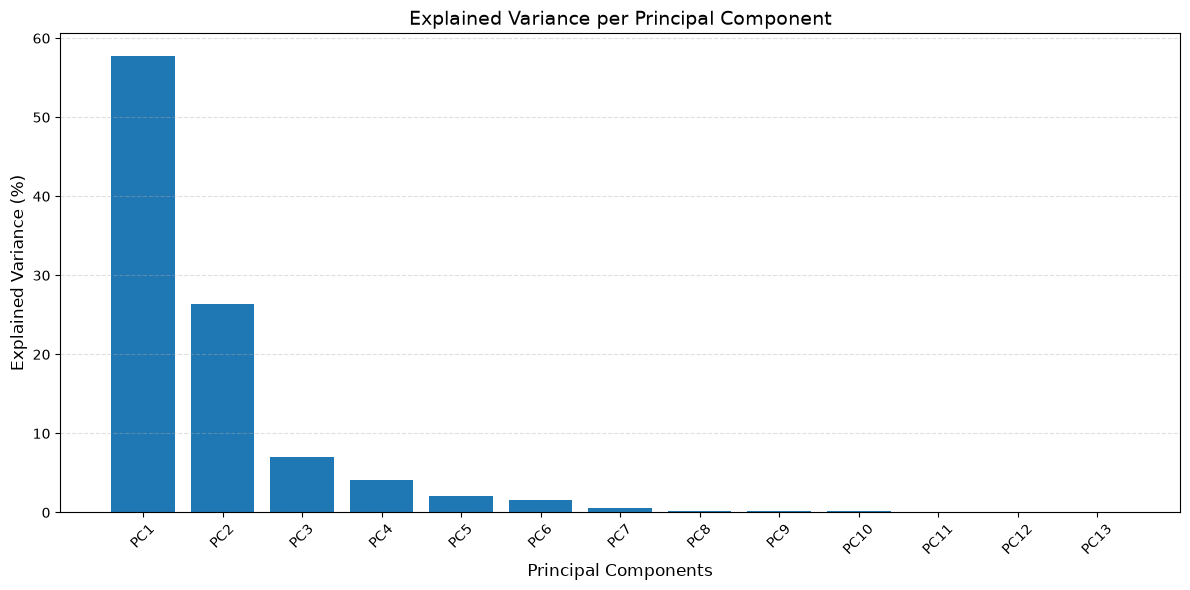

In [68]:
plt.figure(figsize=(12, 6))

plt.bar(
    component_names,
    explained_variance * 100
)

plt.xlabel("Principal Components", fontsize=12)

plt.ylabel("Explained Variance (%)", fontsize=12)

plt.title(
    "Explained Variance per Principal Component",
    fontsize=14
)

plt.xticks(rotation=45)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

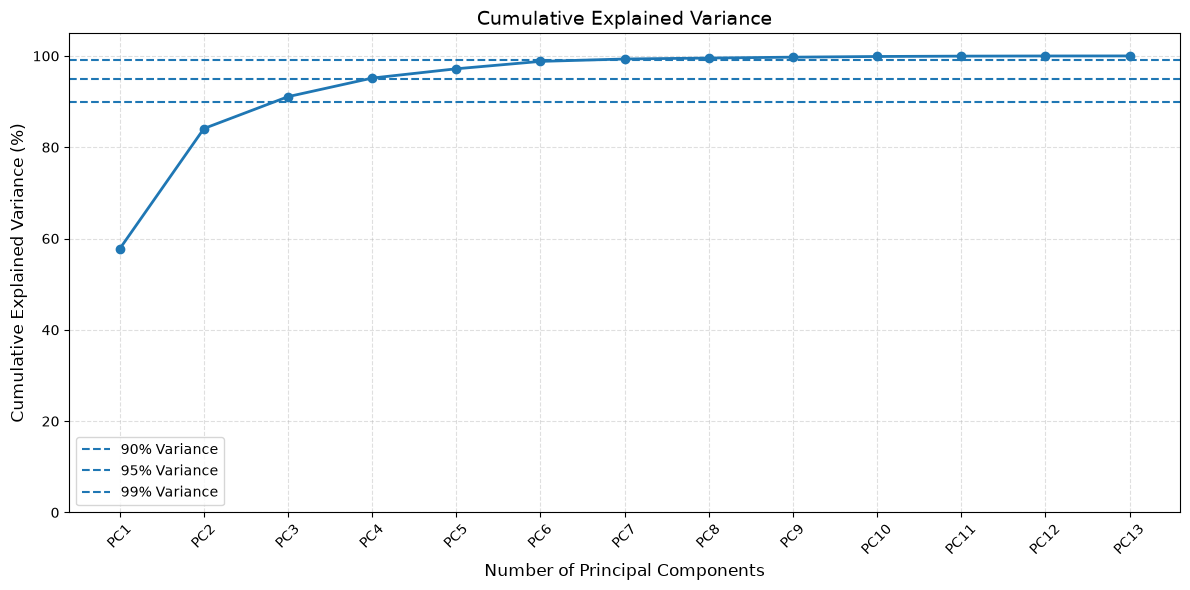

In [69]:
plt.figure(figsize=(12, 6))

plt.plot(
    component_names,
    cumulative_variance * 100,
    marker="o",
    linewidth=2
)

# Variance thresholds
plt.axhline(
    y=90,
    linestyle="--",
    label="90% Variance"
)

plt.axhline(
    y=95,
    linestyle="--",
    label="95% Variance"
)

plt.axhline(
    y=99,
    linestyle="--",
    label="99% Variance"
)

plt.xlabel("Number of Principal Components", fontsize=12)

plt.ylabel("Cumulative Explained Variance (%)", fontsize=12)

plt.title(
    "Cumulative Explained Variance",
    fontsize=14
)

plt.xticks(rotation=45)

plt.ylim(0, 105)

plt.legend()

plt.grid(
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cumulative_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
scaler_path = PCA_OUTPUT_DIR / "scaler.pkl"

pca_path = PCA_OUTPUT_DIR / "pca_transformer.pkl"

joblib.dump(
    scaler,
    scaler_path
)

joblib.dump(
    pca,
    pca_path
)

print("Preprocessing objects saved successfully.")

print("Scaler:", scaler_path)

print("PCA Transformer:", pca_path)

Preprocessing objects saved successfully.
Scaler: C:\Users\HP\Downloads\satellite_empty\satellite_empty\outputs\pca\phase1\scaler.pkl
PCA Transformer: C:\Users\HP\Downloads\satellite_empty\satellite_empty\outputs\pca\phase1\pca_transformer.pkl


In [71]:
print("-" * 20)

print("PHASE 1: PCA ANALYSIS SUMMARY")

print("-" * 20)

print("\nDataset Information")

print("Total samples:", len(samples))

print("Training samples:", len(train_idx))

print("Validation samples:", len(val_idx))

print("Testing samples:", len(test_idx))

print("\nPCA Information")

print("Original spectral bands:", NUM_BANDS)

print("Available components:", pca.n_components_)

print("\nVariance Retention")

for threshold, count in required_components.items():

    print(
        f"{threshold * 100:.0f}%: "
        f"{count} components"
    )

print("\nGenerated Files")

for file_path in [
    variance_csv_path,
    FIGURES_DIR / "explained_variance.png",
    FIGURES_DIR / "cumulative_variance.png",
    scaler_path,
    pca_path
]:

    print(
        file_path.name,
        "->",
        "EXISTS" if file_path.exists() else "MISSING"
    )

print("\nPhase 1 completed.")

--------------------
PHASE 1: PCA ANALYSIS SUMMARY
--------------------

Dataset Information
Total samples: 27000
Training samples: 18900
Validation samples: 4050
Testing samples: 4050

PCA Information
Original spectral bands: 13
Available components: 13

Variance Retention
90%: 3 components
95%: 4 components
99%: 7 components

Generated Files
explained_variance.csv -> EXISTS
explained_variance.png -> EXISTS
cumulative_variance.png -> EXISTS
scaler.pkl -> EXISTS
pca_transformer.pkl -> EXISTS

Phase 1 completed.
